In [ ]:
import bs4
import lxml
import pandas
import urllib
import time

from urllib import request

In [ ]:
#TELECHARGER LE FICHIER
from google.colab import files
files.download("bdd_finale_clean.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
#CHARGER LE FICHIER bdd_finale_clean.csv ver3
from google.colab import files

uploaded = files.upload()

for fn in uploaded.keys():
  print('User uploaded file "{name}" with length {length} bytes'.format(
      name=fn, length=len(uploaded[fn])))

Saving bdd_finale_clean.csv to bdd_finale_clean.csv
User uploaded file "bdd_finale_clean.csv" with length 3540274 bytes


In [ ]:
import pandas as pd
import numpy as np
df = pd.read_csv("bdd_finale_clean.csv")

In [ ]:
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from scipy.sparse import hstack, csr_matrix
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords
import re


df = pd.read_csv("bdd_finale_clean.csv")

# Vérification de la colonne Prix
df["Prix"] = (
    df["Prix"]
    .astype(str)
    .str.replace("€", "", regex=False)
    .str.replace(",", ".", regex=False)
    .str.strip()
)
df["Prix"] = pd.to_numeric(df["Prix"], errors="coerce")
df.loc[df["Prix"] < 0, "Prix"] = np.nan

#Vérification de la colonne Note
df["Note"] = (
    df["Note"]
    .astype(str)
    .str.replace(",", ".", regex=False)
)
df["Note"] = pd.to_numeric(df["Note"], errors="coerce")
df.loc[df["Note"] > 5, "Note"] = np.nan
df.loc[df["Note"] < 0, "Note"] = np.nan

#Vérification de la colonne Avis
df["Avis"] = (
    df["Avis"]
    .astype(str)
    .str.replace("(", "", regex=False)
    .str.replace(")", "", regex=False)
    .str.replace("+", "", regex=False)
    .str.strip()
)
df["Avis"] = pd.to_numeric(df["Avis"], errors="coerce")
df.loc[df["Avis"] < 0, "Avis"] = np.nan


df = df[df["Prix"].notna()].reset_index(drop=True)

# Feature engineering STRUCTURÉ

# Arrondissement par district
df["Arrondissement"] = (
    df["Code postal"]
    .astype(str)
    .str[:-2]
    .astype(float)
)

#Ajout de colonne pour le modele

df["Centre_Paris"] = df["Arrondissement"].isin([1, 2, 3, 4]).astype(int)
df["Zone_touristique"] = df["Arrondissement"].isin([1, 4, 6, 7, 8, 9, 18]).astype(int)

df["note_disponible"] = df["Note"].notna().astype(int)
df["avis_disponible"] = df["Avis"].notna().astype(int)

df["Note"] = df["Note"].fillna(df["Note"].median())
df["log_Avis"] = np.log1p(df["Avis"]).fillna(0)

# Transformation de la colonne Prix catégorie
prix_cat_mapping = {"€": 1, "€€": 2, "€€€": 3, "€€€€": 4}
df["Prix_categorie_num"] = (
    df["Prix catégorie"]
    .map(prix_cat_mapping)
    .fillna(df["Prix catégorie"].map(prix_cat_mapping).median())
)

# Ajout de colonne à partir des variables catégorielles
df["Section"] = df["Section"].astype(str).str.lower()
df["is_menu"] = df["Section"].str.contains("box|plateau|menu", na=False).astype(int) | df["Description"].str.contains("box|plateau|menu", na=False).astype(int) | df["Nom plat"].str.contains("box|plateau|menu", na=False).astype(int)
df["is_best_seller"] = df["Section"].str.contains("best", na=False).astype(int)
df["is_boisson"] = df["Section"].str.contains("boisson|drink|boissons|cl|ml", na=False).astype(int) | df["Description"].str.contains("boisson|drink|boissons|cl|ml", na=False).astype(int)

# ---- Catégories de plats (réduction de cardinalité) ----
seuil = 100
cat_freq = df["Catégorie fixée"].value_counts()
cats_gardees = cat_freq[cat_freq >= seuil].index

df["Categorie_simplifiee"] = np.where(
    df["Catégorie fixée"].isin(cats_gardees),
    df["Catégorie fixée"],
    "Autre"
)

df = pd.get_dummies(
    df,
    columns=["Categorie_simplifiee"],
    drop_first=True
)


df["Nom_plat_clean"] = df["Nom plat"].fillna("").str.lower()
df["Description_clean"] = df["Description"].fillna("").str.lower()

#regroupement de terme similaire pour éviter les doublons
regroupement_termes = {
    "OEUFS": ["œufs", "œuf"],
    "VEGAN" : ['végétarien','végétarienne', 'vegan','veggie'],
    "TOMATE" : ['tomate','tomates'],
    "TEMAKI" : ['temaki','temaki avocat','temaki saumon','temaki thon'],
    "TEMPURA" : ['tempura','tempura crevette'],
    "TARTARE" : ['tartare','tartare saumon'],
    "SUSHIS" : ['sushi','sushi avocat','sushi crevette','sushi daurade','sushi saumon','sushi tartare','sushi thon','sushis','sushis saumon'],
    "SURIMI" : ['surimi','surimi avocat'],
    "SAUMON" : ['saumon','saumon avocat','saumon cheese','saumon fromage','saumon roll'],
    "PIZZA" : ['pizza', 'pizza calzone', 'pizza campione', 'pizza chicken', 'pizza chèvre', 'pizza fromages', 'pizza junior', 'pizza margherita', 'pizza orientale','pizza regina','pizza reine', 'pizza saisons','pizza saumon','pizza senior','pizza végétarienne', 'calzone'],
    "MAKI" : ['maki', 'maki avocat', 'maki cheese', 'maki concombre', 'maki neige', 'maki nutella', 'maki printemps', 'maki radis', 'maki saumon', 'maki thon', 'makis'],
    "CHEESE_BURGER" : ['cheeseburger', 'cheese burger'],
    "CALIFORNIA" : ['california', 'california avocat', 'california crevette', 'california crispy', 'california maki', 'california poulet', 'california royal', 'california saumon', 'california surimi', 'california tempura', 'california thon'],
    "QUANTITE": ["pieces", "pièces",'10','12', '16', '18', '6x', '6x california', '8p'],
    "SUSHI": ["sushi", "california", "maki"],
    "SOUPE": ["soupe", "soupes", "ramen"],
    "BOISSON": ["boisson", "boissons", "drink"]
}

# Création de la colonne avec les mots regroupés
def regrouper_termes(text):
    text = text.lower()
    for groupe, mots in regroupement_termes.items():
        pattern = r"\b(" + "|".join(mots) + r")\b"
        text = re.sub(pattern, groupe, text)
    return text

df["texte_regroupe"] = df["Nom plat"].fillna("").apply(regrouper_termes)

df["texte_plat"] = (
    df["Nom plat"].astype(str).fillna("") + " " +
    df.get("Description", pd.Series(dtype='object')).astype(str).fillna("")
).str.lower()







[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [ ]:
scaler_ing = StandardScaler(with_mean=False)

numeric_features = [
    "Arrondissement",
    "Centre_Paris",
    "Zone_touristique",
    "Note",
    "log_Avis",
    "note_disponible",
    "avis_disponible",
    "Prix_categorie_num",
    "is_menu",
    "is_best_seller",
    "is_boisson"
] + [col for col in df.columns if col.startswith("Categorie_simplifiee_")]

X_num = df[numeric_features]
y = df["Prix"]

# Standardisation
scaler = StandardScaler()
X_num_scaled = scaler.fit_transform(X_num)

# Utilisation d'un dictionnaire de mots français pour répérer des features
french_stop_words = stopwords.words('french')

# TF-IDF sur les mots regroupés

tfidf = TfidfVectorizer(
    ngram_range=(1, 1),
    min_df=10
)

X_text = tfidf.fit_transform(df["texte_regroupe"])


# TF-IDF sur le nom du plat
tfidf_nom = TfidfVectorizer(
    max_features=300,
    ngram_range=(1, 2),
    stop_words=french_stop_words
)

X_nom = tfidf_nom.fit_transform(df["Nom_plat_clean"])

# TF-IDF sur la description
tfidf_desc = TfidfVectorizer(
    max_features=500,
    ngram_range=(1, 2),
    stop_words=french_stop_words
)

X_desc = tfidf_desc.fit_transform(df["Description_clean"])


# TF-IDF sur la section
tfidf_sect = TfidfVectorizer(
    max_features=300,
    ngram_range=(1, 2),
    stop_words=french_stop_words
)
df["Section_clean"] = df["Section"].fillna("").str.lower()

X_sect = tfidf_sect.fit_transform(df["Section_clean"])


X_final = hstack([
    X_nom,
    X_desc,
    X_text,
    X_sect
])

# Sécurité finale pour éviter des erreurs
X_final.data = np.nan_to_num(
    X_final.data,
    nan=0.0,
    posinf=0.0,
    neginf=0.0
)

import numpy as np

# Vérification NaN dans X_final
if np.isnan(X_final.data).any():
    print("❌ NaN détectés dans X_final")
else:
    print("✅ Aucun NaN dans X_final")

# Vérification y
print("NaN dans y :", y.isna().sum())


print("Shape finale du dataset :", X_final.shape)


import joblib

joblib.dump(X_final, "X_features_tfidf.pkl")
joblib.dump(y, "y_prix.pkl")

print("Features TF-IDF et target sauvegardées.")

/usr/local/lib/python3.12/dist-packages/sklearn/utils/extmath.py:1101: RuntimeWarning: invalid value encountered in divide
  updated_mean = (last_sum + new_sum) / updated_sample_count
/usr/local/lib/python3.12/dist-packages/sklearn/utils/extmath.py:1106: RuntimeWarning: invalid value encountered in divide
  T = new_sum / new_sample_count
/usr/local/lib/python3.12/dist-packages/sklearn/utils/extmath.py:1126: RuntimeWarning: invalid value encountered in divide
  new_unnormalized_variance -= correction**2 / new_sample_count


✅ Aucun NaN dans X_final
NaN dans y : 0
Shape finale du dataset : (14122, 1634)
Features TF-IDF et target sauvegardées.


In [ ]:
import joblib
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


X = joblib.load("X_features_tfidf.pkl")
y = joblib.load("y_prix.pkl")


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Taille train :", X_train.shape)
print("Taille test  :", X_test.shape)


model = LinearRegression()
model.fit(X_train, y_train)


y_pred_lr = model.predict(X_test)


mae = mean_absolute_error(y_test, y_pred_lr)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_lr))
r2 = r2_score(y_test, y_pred_lr)

print("📊 Performance du modèle baseline (Linear Regression)")
print(f"MAE  : {mae:.2f} €")
print(f"RMSE : {rmse:.2f} €")
print(f"R²   : {r2:.3f}")


Taille train : (11297, 1634)
Taille test  : (2825, 1634)
📊 Performance du modèle baseline (Linear Regression)
MAE  : 2.96 €
RMSE : 4.94 €
R²   : 0.680


In [ ]:
import joblib
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


X = joblib.load("X_features_tfidf.pkl")
y = joblib.load("y_prix.pkl")


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)


rf = RandomForestRegressor(
    n_estimators=200,
    max_depth=25,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)


y_pred_rf = rf.predict(X_test)


mae = mean_absolute_error(y_test, y_pred_rf)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2 = r2_score(y_test, y_pred_rf)

print("🌳 Performance du Random Forest")
print(f"MAE  : {mae:.2f} €")
print(f"RMSE : {rmse:.2f} €")
print(f"R²   : {r2:.3f}")


🌳 Performance du Random Forest
MAE  : 2.74 €
RMSE : 4.62 €
R²   : 0.721


Visualization for the Interpretation

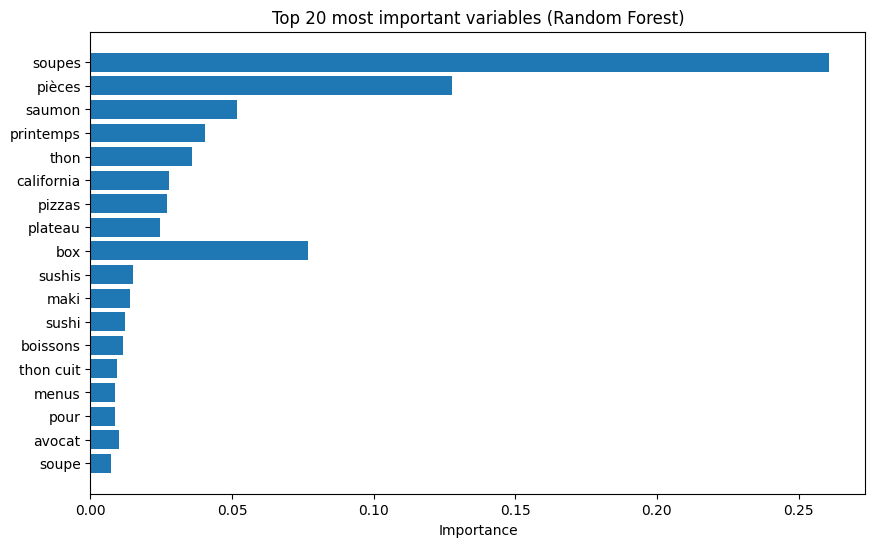

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

feature_names = (
    tfidf_nom.get_feature_names_out().tolist() +
    tfidf_desc.get_feature_names_out().tolist() +
    tfidf.get_feature_names_out().tolist() +
    tfidf_sect.get_feature_names_out().tolist()
)

importances = rf.feature_importances_



df_importance = pd.DataFrame({
    "feature": feature_names,
    "importance": importances
}).sort_values(by="importance", ascending=False)

top_n = 20

plt.figure(figsize=(10, 6))
plt.barh(
    df_importance["feature"].head(top_n)[::-1],
    df_importance["importance"].head(top_n)[::-1]
)
plt.title("Top 20 most important variables (Random Forest)")
plt.xlabel("Importance")
plt.show()

In [ ]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


df_test_results = pd.DataFrame({
    "y_true": y_test.values,
    "y_pred_lr": y_pred_lr,
    "y_pred_rf": y_pred_rf,
    "Catégorie fixée": df.loc[y_test.index, "Catégorie fixée"].values
})

results = []


for categorie in df_test_results["Catégorie fixée"].unique():
    subset = df_test_results[df_test_results["Catégorie fixée"] == categorie]

    # Eviter les catégories trop petites
    if len(subset) < 30:
        continue

    mae_lr = mean_absolute_error(subset["y_true"], subset["y_pred_lr"])
    rmse_lr = np.sqrt(mean_squared_error(subset["y_true"], subset["y_pred_lr"]))
    r2_lr = r2_score(subset["y_true"], subset["y_pred_lr"])

    mae_rf = mean_absolute_error(subset["y_true"], subset["y_pred_rf"])
    rmse_rf = np.sqrt(mean_squared_error(subset["y_true"], subset["y_pred_rf"]))
    r2_rf = r2_score(subset["y_true"], subset["y_pred_rf"])

    results.append({
        "Categorie": categorie,
        "Nb_plats": len(subset),
        "MAE_LR": round(mae_lr, 2),
        "RMSE_LR": round(rmse_lr, 2),
        "R2_LR": round(r2_lr, 3),
        "MAE_RF": round(mae_rf, 2),
        "RMSE_RF": round(rmse_rf, 2),
        "R2_RF": round(r2_rf, 3)
    })

df_results = pd.DataFrame(results)

# Trier par performance Random Forest
df_results = df_results.sort_values("R2_RF", ascending=False)

df_results.head(10)

,Categorie,Nb_plats,MAE_LR,RMSE_LR,R2_LR,MAE_RF,RMSE_RF,R2_RF
2,Sushis,1243,3.38,6.19,0.733,2.62,5.46,0.793
0,Pizzas,728,2.34,3.49,0.505,2.48,3.58,0.477
1,Burger,409,3.06,4.17,0.161,3.16,4.02,0.223
3,Pâtes - IT,318,2.90,3.96,0.204,3.12,4.09,0.149
4,Pâtes - Asie,127,2.66,3.55,0.081,2.64,3.55,0.080


<Figure size 640x480 with 0 Axes>

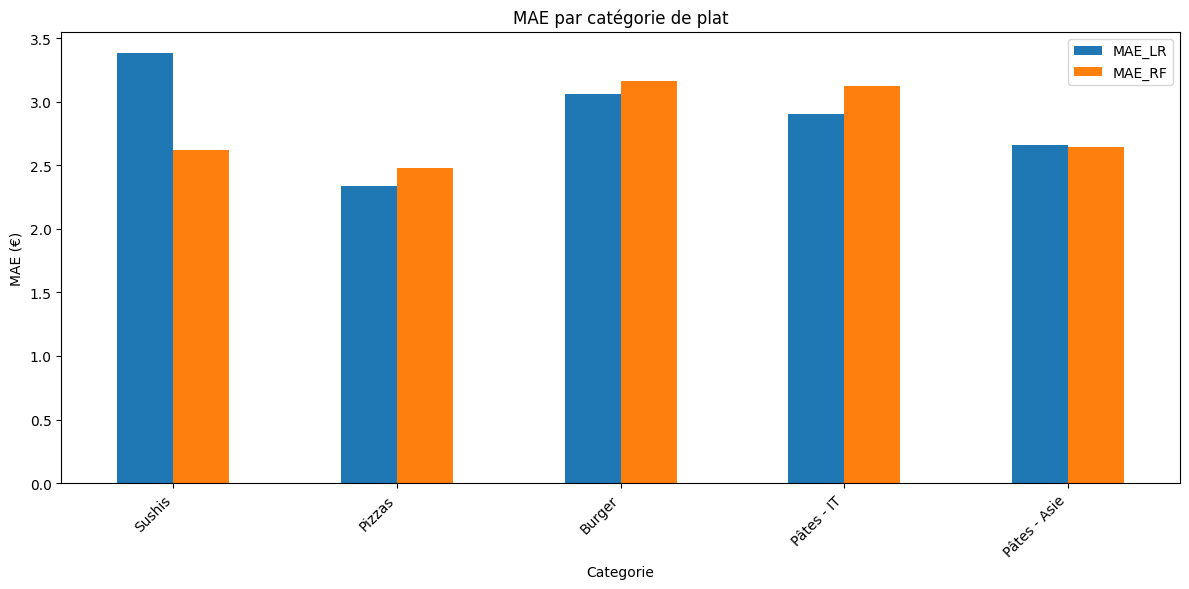

In [ ]:
import matplotlib.pyplot as plt

plt.figure()
df_results.plot(
    x="Categorie",
    y=["MAE_LR", "MAE_RF"],
    kind="bar",
    figsize=(12, 6)
)
plt.ylabel("MAE (€)")
plt.title("MAE par catégorie de plat")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt


df_soup = pd.read_csv("bdd_finale_clean.csv")

# Nettoyage du prix
df_soup["Prix"] = (
    df_soup["Prix"]
    .astype(str)
    .str.replace("€", "", regex=False)
    .str.replace(",", ".", regex=False)
    .str.strip()
)
df_soup["Prix"] = pd.to_numeric(df_soup["Prix"], errors="coerce")

# Fusion des textes (Nom + Description si elle existe)
df_soup["texte_total"] = (
    df_soup.get("Nom plat", "").fillna("").astype(str)
    + " "
    + df_soup.get("Description", "").fillna("").astype(str)
)

# Indicateur présence de "soupe" ou "soupes"
df_soup["has_soupe"] = df_soup["texte_total"].str.contains(
    r"\bsoupe\b|\bsoupes\b", case=False, na=False
)

# Suppression des prix manquants
df_soup = df_soup.dropna(subset=["Prix"])

# Séparation des groupes
prix_soupe = df_soup[df_soup["has_soupe"]]["Prix"]
prix_no_soupe = df_soup[~df_soup["has_soupe"]]["Prix"]


/tmp/ipython-input-2511787927.py:2: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


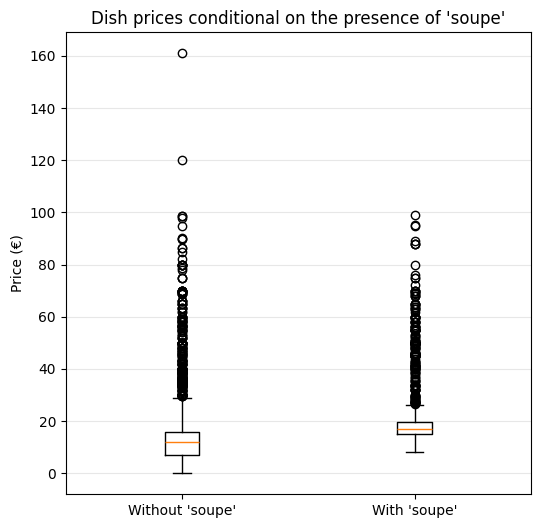

In [ ]:
plt.figure(figsize=(6, 6))
plt.boxplot(
    [prix_no_soupe, prix_soupe],
    labels=["Without 'soupe'", "With 'soupe'"],
    showfliers=True
)
plt.ylabel("Price (€)")
plt.title("Dish prices conditional on the presence of 'soupe'")
plt.grid(axis="y", alpha=0.3)
plt.show()
